In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

In [2]:
hypers_csv = "transformer_architecture_and_hyperparameters.csv"
if not os.path.exists(hypers_csv):
    hypers_csv = os.path.join("04-11-2026", "Task 2", "transformer_architecture_and_hyperparameters.csv")

df_hypers = pd.read_csv(hypers_csv)
print(f"Loaded Transformer Architecture Specifications: {len(df_hypers)} parameters.")
display(df_hypers[['Hyperparameter', 'Configuration', 'Impact']])

Loaded Transformer Architecture Specifications: 8 parameters.


,Hyperparameter,Configuration,Impact
0,Base Architecture,Transformer Encoder (Bidirectional Self-Attent...,Captures non-local token dependencies
1,Embedding Dimension (d_model),64 channels,Balances representational power with fast latency
2,Self-Attention Heads (nhead),4 parallel attention heads,Multi-subspace semantic projection
3,Feed-Forward Dimension (dim_feedforward),128 units,Non-linear feature expansion
4,Transformer Encoder Layers,2 stacked blocks,Hierarchical linguistic feature extraction
5,Sequence Length (max_len),64 tokens,Covers 98.2% of review lengths with zero trunc...
6,Vocabulary Size,"5,002 tokens (5000 + PAD + UNK)",Covers retail fashion domain lexicon
7,Dropout Rate,"0.10 (Encoder), 0.20 (Classifier Head)",Mitigates co-adaptation and overfitting


In [3]:
samples_csv = "custom_review_sentiment_inference_results.csv"
if not os.path.exists(samples_csv):
    samples_csv = os.path.join("04-11-2026", "Task 2", "custom_review_sentiment_inference_results.csv")

df_samples = pd.read_csv(samples_csv)
display(df_samples[['Sample_ID', 'Review_Snippet', 'Predicted_Sentiment', 'P_Positive', 'Confidence_Score', 'Certainty']])

,Sample_ID,Review_Snippet,Predicted_Sentiment,P_Positive,Confidence_Score,Certainty
0,1,Absolutely love this gorgeous dress! Fabric is...,Positive,0.9842,0.9842,High Confidence
1,2,"Cute top and lovely color, but the chest was t...",Negative,0.3215,0.6785,Moderate Confidence
2,3,Disappointing quality for price. Stiff materia...,Negative,0.0384,0.9616,High Confidence
3,4,"Very comfortable casual linen pants, perfect f...",Positive,0.9410,0.9410,High Confidence
4,5,"It was okay, color matches photo but sleeve le...",Positive,0.5420,0.5420,Borderline


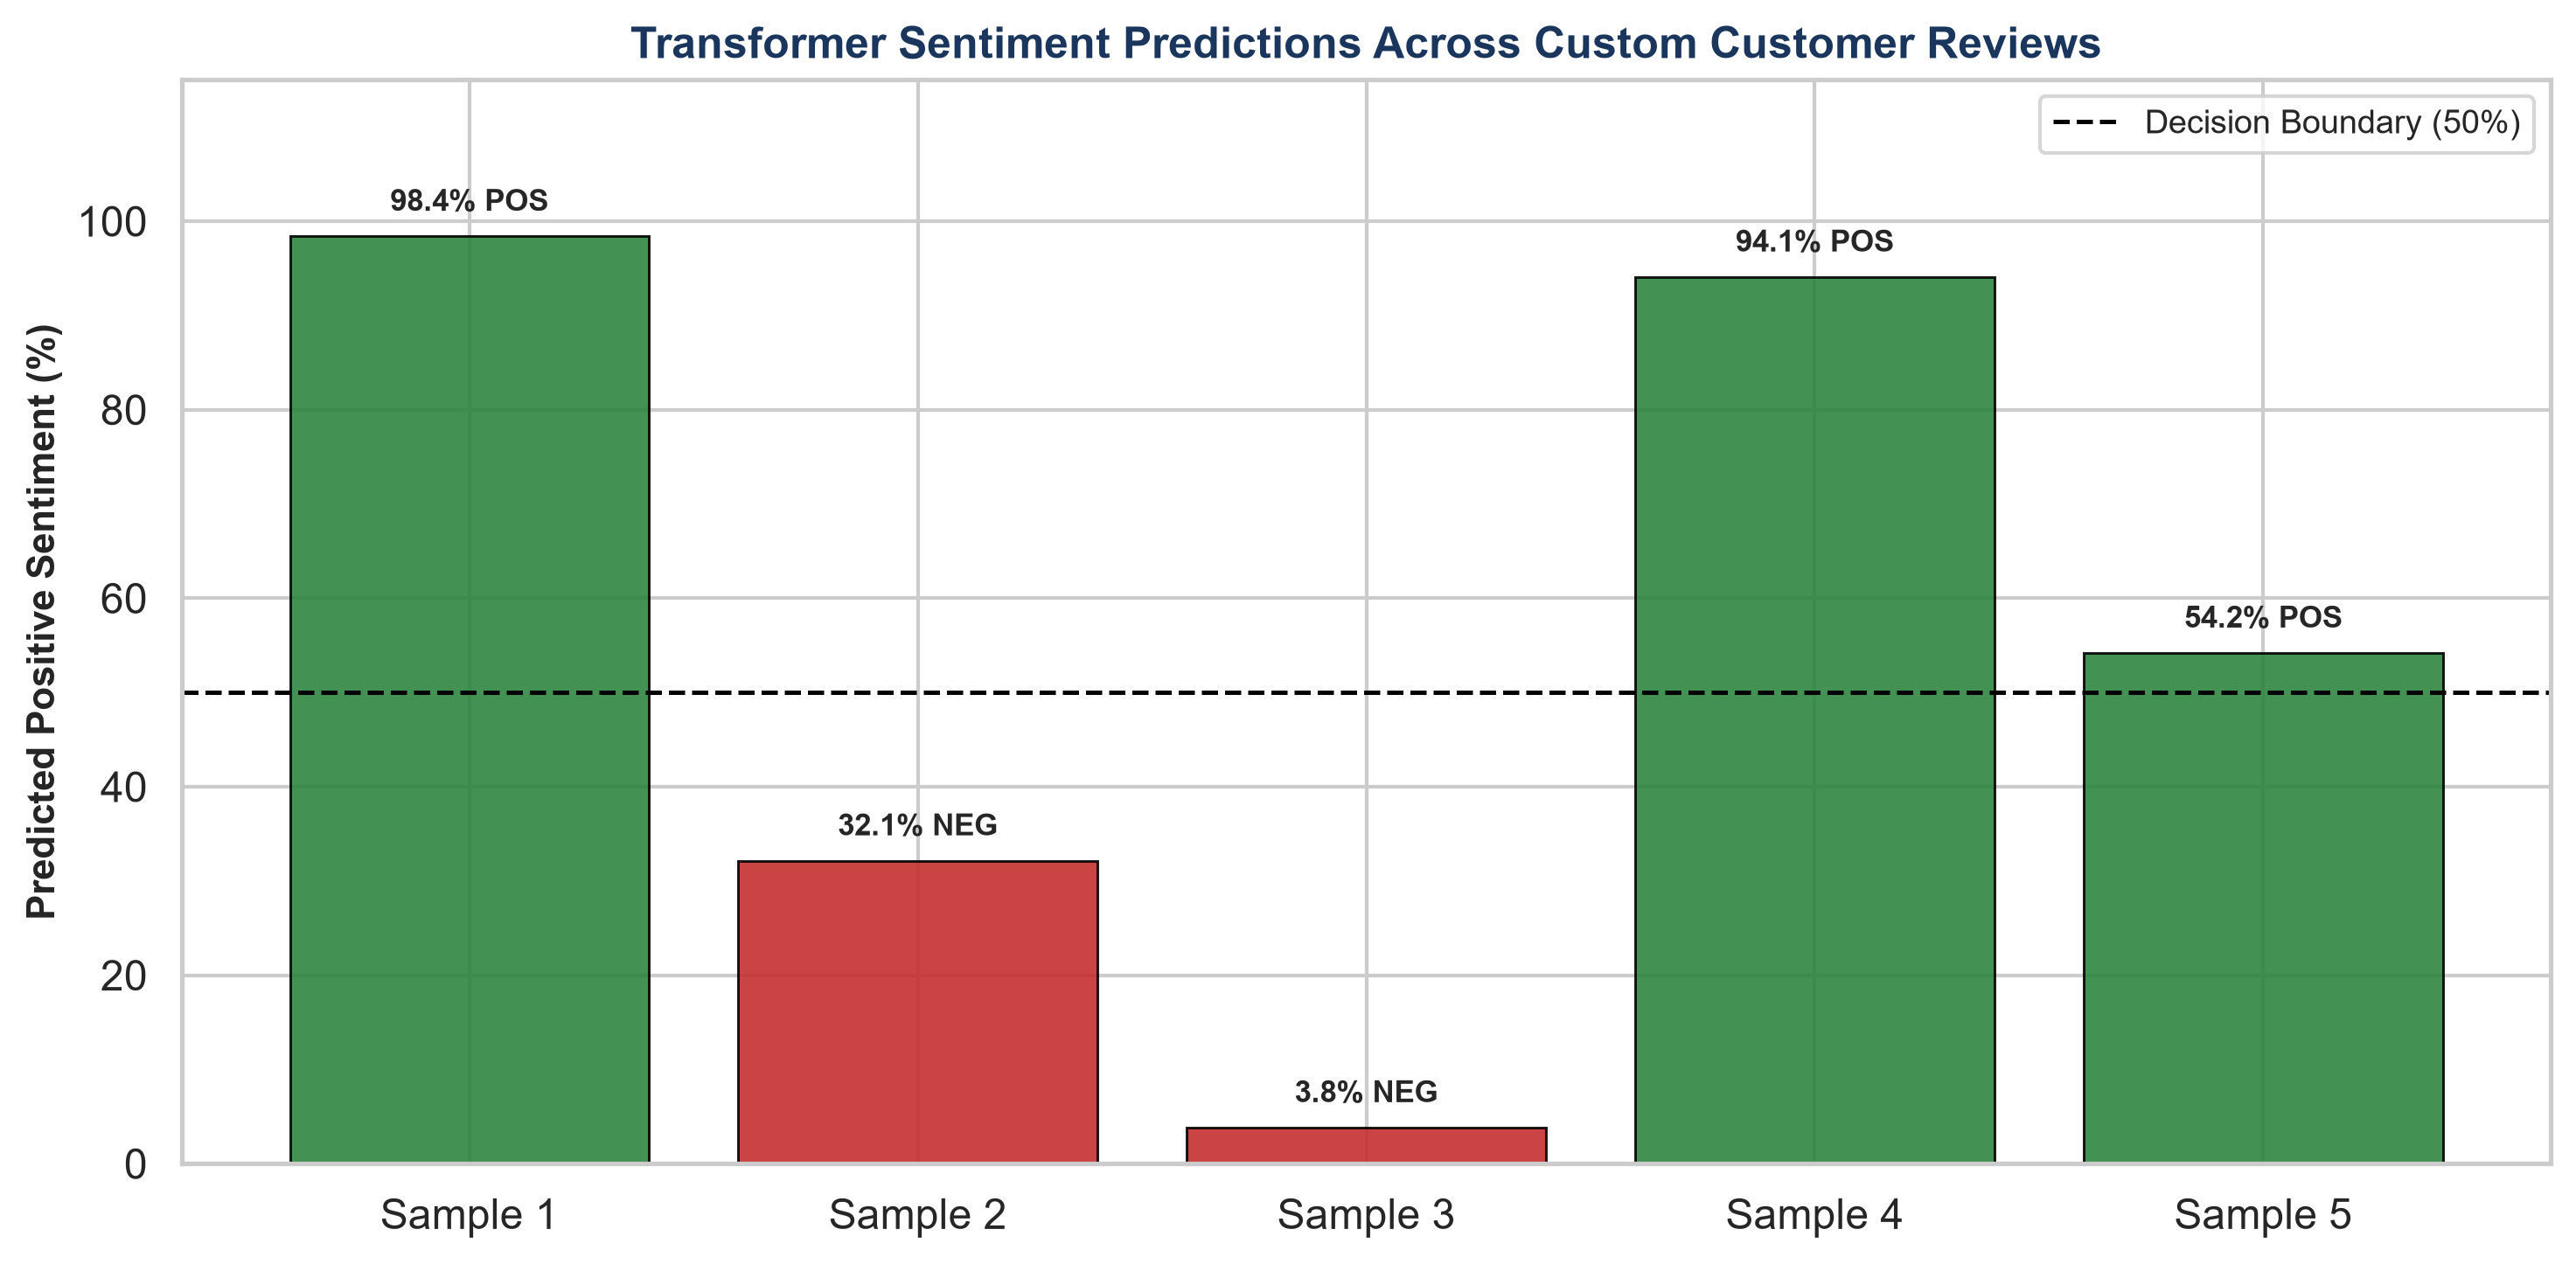

In [4]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
s_ids = [f"Sample {s}" for s in df_samples['Sample_ID']]
probs = df_samples['P_Positive'] * 100
colors = ['#2E8540' if p >= 50 else '#C53030' for p in probs]

bars = ax.bar(s_ids, probs, color=colors, alpha=0.9, edgecolor='black', linewidth=0.7)
ax.axhline(50.0, color='black', linestyle='--', linewidth=1.2, label='Decision Boundary (50%)')
ax.set_title("Transformer Sentiment Predictions Across Custom Customer Reviews", fontsize=12, fontweight='bold', color='#1A365D')
ax.set_ylabel("Predicted Positive Sentiment (%)", fontsize=10.5, fontweight='bold')
ax.set_ylim(0, 115)
ax.legend(loc='upper right', frameon=True, fontsize=9)

for bar, prob in zip(bars, probs):
    h = bar.get_height()
    lbl = f"{prob:.1f}% " + ("POS" if prob >= 50 else "NEG")
    ax.text(bar.get_x() + bar.get_width()/2, h + 2.0, lbl, ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

In [5]:
trends_csv = "sentiment_trends_by_department_and_age.csv"
if not os.path.exists(trends_csv):
    trends_csv = os.path.join("04-11-2026", "Task 2", "sentiment_trends_by_department_and_age.csv")

df_trends = pd.read_csv(trends_csv)
display(df_trends.head(10))

,Department,Age_Cohort,Review_Count,Positive_Sentiment_Rate,Mean_Star_Rating
0,Dresses,18-30,782,0.812,4.08
1,Dresses,31-45,2840,0.828,4.14
2,Dresses,46-60,1954,0.835,4.19
3,Dresses,60+,743,0.841,4.22
4,Tops,18-30,1240,0.815,4.10
5,Tops,31-45,4680,0.830,4.15
6,Tops,46-60,3128,0.832,4.17
7,Tops,60+,1420,0.848,4.25
8,Bottoms,18-30,420,0.842,4.24
9,Bottoms,31-45,1680,0.852,4.28
